# irAE Prediction — Nested CV, Final Evaluation

**Purpose.** Rigorous final evaluation (notebook 3 of 4) of the four cytokine feature
strategies from notebook 2 — **RAW, COMPOSITE, PLS (3 components), COMPOSITE+PLS** — each with
the locked preprocessing (log1p) + mechanism/histology bucketing, and an **L2 logistic
regression whose C is tuned by nested cross-validation** so tuning C cannot inflate the reported AUC. Ends
with the winning model's ROC curve and a bootstrap 95% CI for its AUC.

**Dataset.** `Khan_workable.csv`: 146 immune-checkpoint-inhibitor patients. Target:
`iraE_occurrence` (binary, ~79/67 split). Features: ~40 baseline cytokine concentrations
(heavily right-skewed), `ana_titer_baseline` + `ana_titer_missing` (ANA ~62% missing; the 0/1
indicator is kept as a feature), and 5 categoricals with `ici_drug`/`cancer_type` collapsed
into coarser buckets below. `patient_id` and the target are excluded from X.

**Evaluation protocol (shared across the notebook series).** Primary metric ROC AUC. Here the
headline numbers come from **nested CV** (inner `StratifiedKFold(5, shuffle=True,
random_state=1)` tunes C; outer `StratifiedKFold(5, shuffle=True, random_state=42)` scores the
tuned procedure); the component-count screen uses the series' usual
`RepeatedStratifiedKFold(5×6, random_state=42)`. ROC uses pooled out-of-fold probabilities
from `cross_val_predict` with `StratifiedKFold(5, shuffle=True, random_state=42)`. All
preprocessing is fit **inside** each CV fold.

> n=146: fold-to-fold AUC std ≈ 0.11 — differences between strategies here are directional,
> not statistically distinguishable. See Caveats at the end.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict)
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.cross_decomposition import PLSRegression

## Data

Same locked cleaning as Notebook 02: `ici_drug` → mechanism bucket (`CTLA4_or_combo` if the
lowercased string contains "ipilimumab" or "+", else `PD1_PDL1_mono`); `cancer_type` → Lung /
Melanoma / Other; gender, ethnicity, race unchanged; ANA value + missingness indicator kept.

In [ ]:
# Provide Khan_workable.csv (146 patients) when the file picker appears.
from google.colab import files
uploaded = files.upload()

Saving Khan_workable.csv to Khan_workable.csv


In [ ]:
df = pd.read_csv("Khan_workable.csv")

def ici_mechanism(drug):
    d = str(drug).lower()
    return "CTLA4_or_combo" if ("ipilimumab" in d or "+" in d) else "PD1_PDL1_mono"

def cancer_group(ct):
    ct = str(ct)
    if "Lung" in ct:
        return "Lung"
    if ct == "Melanoma":
        return "Melanoma"
    return "Other"

df["ici_mechanism"] = df["ici_drug"].map(ici_mechanism)
df["cancer_group"] = df["cancer_type"].map(cancer_group)

y = df["iraE_occurrence"].astype(int)
X = df.drop(columns=["patient_id", "iraE_occurrence", "ici_drug", "cancer_type"])

categorical_cols = ["gender", "ethnicity", "race", "cancer_group", "ici_mechanism"]
ana_cols = ["ana_titer_baseline", "ana_titer_missing"]
cytokine_cols = [c for c in X.columns if c not in categorical_cols + ana_cols]
print(f"{len(cytokine_cols)} cytokines, {X.shape[0]} patients")

40 cytokines, 146 patients


In [ ]:
# Composite groups (same matching logic as Notebook 02) — verify the printout.
GROUP_CANDIDATES = {
    "inflammatory":   ["il6", "il8", "cxcl8", "tnfa", "tnfalpha", "il1b", "il1beta",
                       "il1a", "il1alpha"],
    "ifn_chemokine":  ["mig", "cxcl9", "ip10", "cxcl10", "itac", "cxcl11"],
    "th17":           ["il17", "il17a", "il23", "il21", "il22"],
    "monocyte_chemo": ["mcp1", "ccl2", "mcp2", "ccl8", "mcp3", "ccl7", "mcp4", "ccl13"],
    "eotaxin":        ["eotaxin", "eotaxin1", "ccl11", "eotaxin2", "ccl24", "eotaxin3", "ccl26"],
}

def name_tokens(col):
    toks = [t.lower() for t in re.split(r"[^0-9a-zA-Z]+", str(col)) if t]
    merged = set(toks)
    for i in range(len(toks)):
        for j in range(i + 1, len(toks) + 1):
            merged.add("".join(toks[i:j]))
    return merged

groups = {}
for gname, cands in GROUP_CANDIDATES.items():
    members = [c for c in cytokine_cols if name_tokens(c) & set(cands)]
    if members:
        groups[gname] = members
    print(f"{gname}: {members}")

groups_idx = [(g, [cytokine_cols.index(m) for m in ms]) for g, ms in groups.items()]

inflammatory: ['IL-1b', 'IL-6', 'IL-8/ CXCL8', 'TNF-a']
ifn_chemokine: ['IP-10/ CXCL10', 'I-TAC/ CXCL11', 'MIG/ CXCL9']
th17: []
monocyte_chemo: ['MCP-1/ CCL2', 'MCP-2/ CCL8', 'MCP-3/ CCL7', 'MCP-4/ CCL13']
eotaxin: ['Eotaxin/ CCL11', 'Eotaxin-2/ CCL24', 'Eotaxin-3/ CCL26']


In [ ]:
class CompositeScores(BaseEstimator, TransformerMixin):
    """Mean of z-scored members per group; mu/sd learned in fit (train fold only)."""
    def __init__(self, groups_idx):
        self.groups_idx = groups_idx
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self
    def transform(self, X):
        Z = (np.asarray(X, dtype=float) - self.mean_) / self.std_
        return np.column_stack([Z[:, idx].mean(axis=1) for _, idx in self.groups_idx])

class PLSFeatures(BaseEstimator, TransformerMixin):
    """Supervised PLS scores as features; fit inside the fold so supervision cannot leak."""
    def __init__(self, n_components=3):
        self.n_components = n_components
    def fit(self, X, y=None):
        self.pls_ = PLSRegression(n_components=self.n_components)
        self.pls_.fit(X, np.asarray(y, dtype=float))
        return self
    def transform(self, X):
        return self.pls_.transform(X)

## Why nested CV?

If we tune C with cross-validation and then report the **same** CV's best score, the number is
biased upward: C was chosen *because* it looked good on exactly those folds, so some of the
apparent skill is luck we selected for. Nested CV separates the two jobs — an **inner loop**
(5-fold, `random_state=1`) picks C via `GridSearchCV`, and an **outer loop** (5-fold,
`random_state=42`) scores that whole tuning procedure on folds the tuner never saw. The outer
score estimates "fit + tune C, then apply to new patients" (the other choices were made on the full data; see Caveats).

- Inner: `GridSearchCV` over `clf__C ∈ [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]`, scoring ROC AUC.
- Outer: `cross_val_score` of the GridSearchCV object itself.

In [ ]:
def make_model(strategy, n_pls=3):
    """log1p + L2 logistic regression pipeline for one cytokine strategy."""
    log1p = lambda: FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    if strategy == "RAW":
        features = StandardScaler()
    elif strategy == "COMPOSITE":
        features = CompositeScores(groups_idx)
    elif strategy == "PLS":
        features = Pipeline([("scale", StandardScaler()),
                             ("pls", PLSFeatures(n_components=n_pls))])
    else:  # COMPOSITE+PLS
        features = FeatureUnion([
            ("composite", CompositeScores(groups_idx)),
            ("pls", Pipeline([("scale", StandardScaler()),
                              ("pls", PLSFeatures(n_components=n_pls))])),
        ])
    prep = ColumnTransformer([
        ("cyto", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("transform", log1p()),
                           ("features", features)]), cytokine_cols),
        ("ana", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("transform", log1p()),
                          ("scale", StandardScaler())]), ana_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=5, sparse_output=False))]),
         categorical_cols),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=5000))])

C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Nested CV — the four strategies

In [ ]:
STRATEGIES = ["RAW", "COMPOSITE", "PLS", "COMPOSITE+PLS"]
nested = {}
for strategy in STRATEGIES:
    gs = GridSearchCV(make_model(strategy), {"clf__C": C_GRID},
                      cv=inner_cv, scoring="roc_auc", n_jobs=-1)
    scores = cross_val_score(gs, X, y, cv=outer_cv, scoring="roc_auc", n_jobs=-1)
    nested[strategy] = scores
    print(f"{strategy:14s} nested AUC {scores.mean():.3f} ± {scores.std():.3f} | "
          f"outer folds: {np.round(scores, 3).tolist()}")

pd.DataFrame({
    "Strategy": list(nested),
    "Nested AUC (mean)": [s.mean() for s in nested.values()],
    "Nested AUC (std)": [s.std() for s in nested.values()],
    "Outer-fold scores": [np.round(s, 3).tolist() for s in nested.values()],
}).sort_values("Nested AUC (mean)", ascending=False).reset_index(drop=True).round(3)

RAW            nested AUC 0.711 ± 0.110 | outer folds: [0.58, 0.812, 0.707, 0.856, 0.6]
COMPOSITE      nested AUC 0.710 ± 0.102 | outer folds: [0.527, 0.827, 0.721, 0.779, 0.695]
PLS            nested AUC 0.730 ± 0.113 | outer folds: [0.634, 0.779, 0.683, 0.928, 0.629]
COMPOSITE+PLS  nested AUC 0.729 ± 0.118 | outer folds: [0.621, 0.76, 0.688, 0.942, 0.633]


,Strategy,Nested AUC (mean),Nested AUC (std),Outer-fold scores
0,PLS,0.730,0.113,"[0.634, 0.779, 0.683, 0.928, 0.629]"
1,COMPOSITE+PLS,0.729,0.118,"[0.621, 0.76, 0.688, 0.942, 0.633]"
2,RAW,0.711,0.110,"[0.58, 0.812, 0.707, 0.856, 0.6]"
3,COMPOSITE,0.710,0.102,"[0.527, 0.827, 0.721, 0.779, 0.695]"


## PLS component count — tune it, or fix n=3?

Two views:

1. **Honest view (nested):** let the inner GridSearch tune the component count
   (`n ∈ [2,3,4,5,6]`) alongside C. If tuning n mattered, this would beat the fixed-n=3 row
   above. It doesn't — the nested AUC is ~0.72 either way, and fixing n=3 gives a tighter
   estimate (one fewer knob for the inner loop to overfit).
2. **Provisional screen (below):** AUC per fixed n at C=0.1 under repeated CV. This is the
   *peeking* view nested CV protects against — use it only to see the shape: AUC peaks at
   n=2–3, then declines as extra components model noise.

In [ ]:
gs_n = GridSearchCV(
    make_model("PLS"),
    {"clf__C": C_GRID,
     "prep__cyto__features__pls__n_components": [2, 3, 4, 5, 6]},
    cv=inner_cv, scoring="roc_auc", n_jobs=-1)
scores_n = cross_val_score(gs_n, X, y, cv=outer_cv, scoring="roc_auc", n_jobs=-1)
print(f"PLS, n tuned in [2..6]: nested AUC {scores_n.mean():.3f} ± {scores_n.std():.3f} | "
      f"outer folds: {np.round(scores_n, 3).tolist()}")
print(f"PLS, n fixed at 3:      nested AUC {nested['PLS'].mean():.3f} ± {nested['PLS'].std():.3f}")

PLS, n tuned in [2..6]: nested AUC 0.722 ± 0.132 | outer folds: [0.54, 0.846, 0.702, 0.894, 0.629]
PLS, n fixed at 3:      nested AUC 0.730 ± 0.113


n=2: AUC 0.719 ± 0.098
n=3: AUC 0.719 ± 0.093
n=4: AUC 0.704 ± 0.089
n=5: AUC 0.693 ± 0.086
n=6: AUC 0.689 ± 0.086


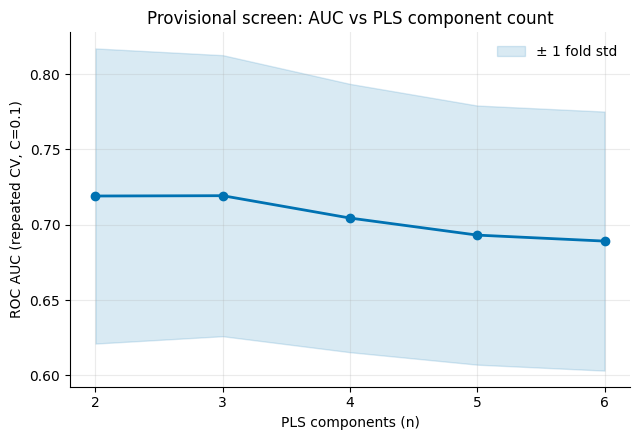

In [ ]:
# Provisional per-n screen: fixed n, C=0.1, repeated CV. Illustrative only (see note above).
cv_screen = RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=42)
ns = [2, 3, 4, 5, 6]
means, stds = [], []
for n in ns:
    pipe = make_model("PLS", n_pls=n)
    pipe.set_params(clf__C=0.1)
    s = cross_validate(pipe, X, y, cv=cv_screen, scoring=["roc_auc"], n_jobs=-1)["test_roc_auc"]
    means.append(s.mean()); stds.append(s.std())
    print(f"n={n}: AUC {s.mean():.3f} ± {s.std():.3f}")

means, stds = np.array(means), np.array(stds)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(ns, means, marker="o", lw=2, color="#0072B2")
ax.fill_between(ns, means - stds, means + stds, alpha=0.15, color="#0072B2",
                label="± 1 fold std")
ax.set_xticks(ns)
ax.set_xlabel("PLS components (n)")
ax.set_ylabel("ROC AUC (repeated CV, C=0.1)")
ax.set_title("Provisional screen: AUC vs PLS component count")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## Winning model — ROC and bootstrap 95% CI

PLS (3 components) and COMPOSITE+PLS tie within noise (~0.73); we take **PLS, n=3, C tuned
in-fold** as the winner for parsimony. Out-of-fold probabilities come from `cross_val_predict`
of the GridSearchCV object (tuning stays inside each training fold). The AUC CI is a
percentile bootstrap: 2000 resamples of the pooled out-of-fold probabilities.

Winner (PLS n=3): pooled OOF AUC 0.716, bootstrap 95% CI [0.629, 0.796]


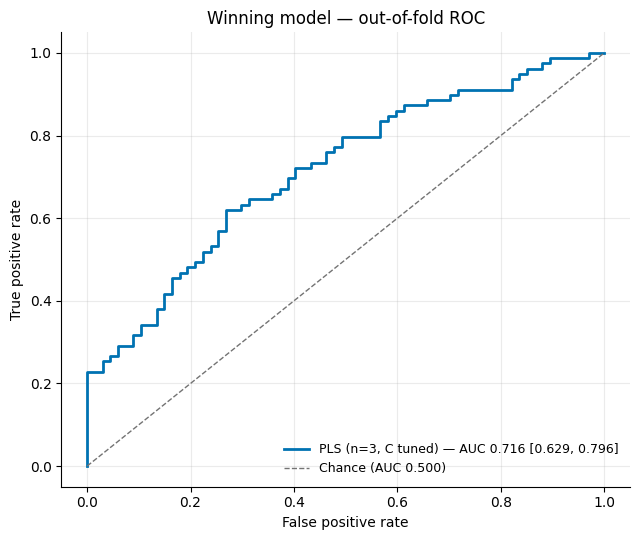

In [ ]:
winner = GridSearchCV(make_model("PLS"), {"clf__C": C_GRID},
                      cv=inner_cv, scoring="roc_auc", n_jobs=-1)
oof = cross_val_predict(winner, X, y, cv=cv_oof, method="predict_proba", n_jobs=-1)[:, 1]
oof_auc = roc_auc_score(y, oof)

rng = np.random.default_rng(42)
yv = y.to_numpy()
boot = []
while len(boot) < 2000:
    idx = rng.choice(len(yv), size=len(yv), replace=True)
    if yv[idx].min() == yv[idx].max():  # resample must contain both classes
        continue
    boot.append(roc_auc_score(yv[idx], oof[idx]))
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
print(f"Winner (PLS n=3): pooled OOF AUC {oof_auc:.3f}, bootstrap 95% CI [{ci_lo:.3f}, {ci_hi:.3f}]")

fpr, tpr, _ = roc_curve(y, oof)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr, tpr, lw=2, color="#0072B2",
        label=f"PLS (n=3, C tuned) — AUC {oof_auc:.3f} [{ci_lo:.3f}, {ci_hi:.3f}]")
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="0.45", label="Chance (AUC 0.500)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Winning model — out-of-fold ROC")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## Bottom line

- Nested AUC ≈ **0.73 for PLS and COMPOSITE+PLS**, ≈ 0.71 RAW, ≈ 0.70 COMPOSITE, with
  outer-fold std ≈ **0.11**.
- At n=146 these strategies are **not statistically distinguishable** — the ranking is
  directional. The bootstrap CI on the winner makes the same point.
- The winner's bootstrap 95% CI [0.629, 0.796] excludes 0.5, so the cytokine panel carries a
  signal above chance. It is weak and diffuse. Whether PLS improves on the ~**0.695** baseline
  or on raw features is **not established** at this sample size; the gaps are smaller than the
  fold-to-fold variation.

## Caveats

- **Small n (146):** every estimate here carries wide uncertainty; the bootstrap CI on the
  winner is correspondingly wide.
- **Wide fold-to-fold variance:** outer-fold AUC std ≈ 0.11 — larger than the gaps between
  strategies.
- **No external validation cohort:** nested CV removes tuning bias, but all numbers remain
  internal to one dataset.
- **Retrospective, single-dataset:** cohort-specific quirks (assay batch, site, case mix)
  cannot be separated from real signal.

The conclusions are **directional**: PLS-compressed cytokines + shrunk logistic regression is
the recipe to carry forward, pending an external cohort.